In [1]:
import numpy as np
import random
import matplotlib.pyplot as plt
import time
from IPython.display import clear_output

# Configuración para matplotlib en Colab
%matplotlib inline

In [2]:
# Tamaño del tablero
GRID_SIZE = 9
CELL_SIZE = 50

# Sudoku predefinido (0 representa casillas vacías)
sudoku_puzzle = [
    [5, 3, 0, 0, 7, 0, 0, 0, 0],
    [6, 0, 0, 1, 9, 5, 0, 0, 0],
    [0, 9, 8, 0, 0, 0, 0, 6, 0],
    [8, 0, 0, 0, 6, 0, 0, 0, 3],
    [4, 0, 0, 8, 0, 3, 0, 0, 1],
    [7, 0, 0, 0, 2, 0, 0, 0, 6],
    [0, 6, 0, 0, 0, 0, 2, 8, 0],
    [0, 0, 0, 4, 1, 9, 0, 0, 5],
    [0, 0, 0, 0, 8, 0, 0, 7, 9]
]

In [3]:
import numpy as np
import random
import matplotlib.pyplot as plt
import time
from IPython.display import clear_output

# Posiciones de los números fijos
fixed_positions = {(r, c) for r in range(GRID_SIZE) for c in range(GRID_SIZE) if sudoku_puzzle[r][c] != 0}

def draw_grid(grid, generation, fitness_score):
    """Dibuja el Sudoku usando Matplotlib"""
    clear_output(wait=True)
    plt.figure(figsize=(8, 8))
    plt.title(f"Generación: {generation} - Fitness: {fitness_score}", fontsize=14)
    plt.gca().set_facecolor((0.8, 0.8, 0.8))  # RGB: 0.8 es un gris claro

    # Dibujar cuadrícula
    for r in range(GRID_SIZE + 1):
        lw = 2 if r % 3 == 0 else 0.5
        plt.plot([0, GRID_SIZE], [r, r], 'k', linewidth=lw)
        plt.plot([r, r], [0, GRID_SIZE], 'k', linewidth=lw)

    # Añadir números
    for r in range(GRID_SIZE):
        for c in range(GRID_SIZE):
            if grid[r][c] != 0:
                color = 'darkred' if (r, c) in fixed_positions else 'darkblue'
                plt.text(c + 0.5, GRID_SIZE - r - 0.5, str(grid[r][c]),
                        ha='center', va='center', fontsize=14, color=color, fontweight='bold')

    plt.xticks([])
    plt.yticks([])
    plt.show()
    plt.close()  # Cerrar figura para liberar memoria

def generate_population(size):
    """Genera población inicial donde cada fila tiene los números del 1 al 9 exactamente una vez"""
    population = []
    for _ in range(size):
        grid = np.zeros((9, 9), dtype=int)
        for r in range(9):
            # Números que ya están fijos en esta fila
            fixed_nums = [sudoku_puzzle[r][c] for c in range(9) if (r, c) in fixed_positions]
            # Números que faltan en esta fila
            available_nums = [num for num in range(1, 10) if num not in fixed_nums]
            random.shuffle(available_nums)

            for c in range(9):
                if (r, c) in fixed_positions:
                    grid[r][c] = sudoku_puzzle[r][c]
                else:
                    grid[r][c] = available_nums.pop()
        population.append(grid)
    return population

def get_subgrids(grid):
    """Transforma el grid para agrupar las subcuadrículas de 3x3 en filas"""
    subgrids = []
    for box_row in range(3):
        for box_col in range(3):
            subgrid = []
            for r in range(box_row * 3, box_row * 3 + 3):
                for c in range(box_col * 3, box_col * 3 + 3):
                    subgrid.append(grid[r][c])
            subgrids.append(subgrid)
    return np.array(subgrids)

def fitness(grid):
    """Calcula fitness basado en números únicos por filas, columnas y penalización de subcuadrículas"""
    row_unique = sum(len(set(row)) for row in grid)
    col_unique = sum(len(set(col)) for col in grid.T)

    grid_ = get_subgrids(grid)
    subgrid_unique = 81 - sum(len(set(subgrid)) for subgrid in grid_)

    return row_unique + col_unique - subgrid_unique - (81 - col_unique)*2

def fitness_best(grid):
    """Calcula fitness basado en números únicos por filas, columnas y penalización de subcuadrículas"""
    row_unique = sum(len(set(row)) for row in grid)
    col_unique = sum(len(set(col)) for col in grid.T)

    grid_ = get_subgrids(grid)
    subgrid_unique = 81 - sum(len(set(subgrid)) for subgrid in grid_)

    print(f"filas:{row_unique} | columnas:{col_unique} | subgrid:{subgrid_unique}")

    return row_unique + col_unique - subgrid_unique - (81 - col_unique)*2

def crossover_mask(p1, p2):
    """Cruzamiento por filas con probabilidad 50%"""
    mask = np.random.rand(9) < 0.5
    child = np.where(mask[:, None], p1, p2)
    return child

def crossover_arithmetic(p1, p2, alpha=0.5):
    """Cruzamiento aritmético: Hijo = alpha * p1 + (1 - alpha) * p2 rounded to nearest integer"""
    child_float = alpha * p1 + (1 - alpha) * p2
    child = np.clip(np.round(child_float), 1, 9).astype(int)
    # Asegurar que se mantengan los valores fijos originales
    for r in range(GRID_SIZE):
        for c in range(GRID_SIZE):
            if (r, c) in fixed_positions:
                child[r][c] = sudoku_puzzle[r][c]
    return child

def crossover_box(p1, p2):
    """Cruzamiento de subcuadrículas 3x3 (Box-level Crossover)"""
    child = p1.copy()
    for box_row in range(3):
        for box_col in range(3):
            # Seleccionar de forma aleatoria (50% de probabilidad) heredar esta caja del Padre 2
            if random.random() < 0.5:
                r_start, r_end = box_row * 3, box_row * 3 + 3
                c_start, c_end = box_col * 3, box_col * 3 + 3
                child[r_start:r_end, c_start:c_end] = p2[r_start:r_end, c_start:c_end]
    return child

def mutate(grid, mutation_rate=0.05):
    """Mutación respetando números fijos"""
    mutation_mask = np.random.rand(*grid.shape) < mutation_rate
    random_values = np.random.randint(1, 10, grid.shape)
    return np.where(mutation_mask & ~np.array([[ (r,c) in fixed_positions
                                               for c in range(9)] for r in range(9)]),
                   random_values, grid)

def genetic_algorithm(pop_size=100, max_generations=1000, mutation_rate=0.05, stagnation_limit=50):
    """Algoritmo genético principal con cruzamientos aleatorios e inmigración por estancamiento"""
    population = generate_population(pop_size)
    best_overall_fitness = -999999
    generations_without_improvement = 0

    for generation in range(max_generations):
        # Evaluar y ordenar población
        population.sort(key=lambda x: -fitness(x))
        best_solution = population[0]
        current_fitness = fitness(best_solution)

        # Control de estancamiento
        if current_fitness > best_overall_fitness:
            best_overall_fitness = current_fitness
            generations_without_improvement = 0
        else:
            generations_without_improvement += 1

        # Mostrar progreso cada 10 generaciones
        if generation % 10 == 0:
            draw_grid(best_solution, generation, current_fitness)
            print(f"Generación: {generation:4d} | Fitness: {current_fitness:3d} | Sin mejora: {generations_without_improvement}/{stagnation_limit} | Máximo: 162")
            print("Mejor solución hasta ahora:")
            fitness_best(best_solution)
            print(best_solution)
            time.sleep(0.1)

        # Condición de término
        if current_fitness == 162:
            print("¡Sudoku resuelto!")
            draw_grid(best_solution, generation, current_fitness)
            return best_solution

        # Inmigración Inteligente si hay estancamiento (reemplaza el 30% peor)
        if generations_without_improvement >= stagnation_limit:
            num_immigrants = int(pop_size * 0.3)
            # El 70% superior se conserva, el 30% inferior es reemplazado por nuevos individuos inteligentes
            population = population[:-num_immigrants] + generate_population(num_immigrants)
            generations_without_improvement = 0
            print(f"¡Estancamiento detectado! Se han introducido {num_immigrants} nuevos inmigrantes inteligentes.")

        # Selección y reproducción
        parents = population[:max(2, int(pop_size * 0.01))]
        new_pop = [best_solution.copy()]

        while len(new_pop) < pop_size:
            p1, p2 = random.choices(parents, k=2)

            # Selección probabilística del tipo de crossover
            # Actualmente el crossover de subcuadrículas (crossover_box) tiene prob = 1.0
            r_val = random.random()
            if r_val < 0.4:
                child = crossover_box(p1, p2)
            elif r_val < 0.5: # Reemplazar límites en el futuro para dar paso a los otros crossovers
                child = crossover_mask(p1, p2)
            else:
                child = crossover_arithmetic(p1, p2, alpha=random.random())

            child = mutate(child, mutation_rate)
            new_pop.append(child)

        population = new_pop

    best_solution = population[0]
    print("Máximo de generaciones alcanzado. Solución no encontrada.")
    draw_grid(best_solution, max_generations, fitness(best_solution))
    return best_solution

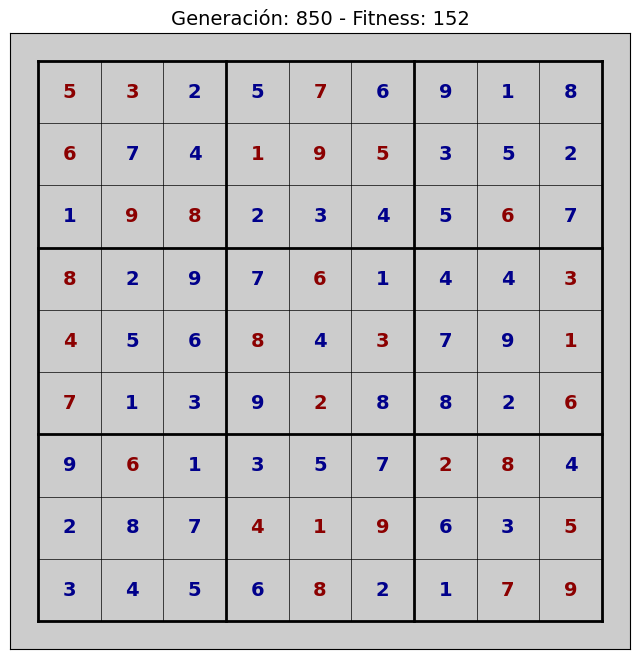

Generación:  850 | Fitness: 152 | Sin mejora: 27/50 | Máximo: 162
Mejor solución hasta ahora:
filas:75 | columnas:81 | subgrid:4
[[5 3 2 5 7 6 9 1 8]
 [6 7 4 1 9 5 3 5 2]
 [1 9 8 2 3 4 5 6 7]
 [8 2 9 7 6 1 4 4 3]
 [4 5 6 8 4 3 7 9 1]
 [7 1 3 9 2 8 8 2 6]
 [9 6 1 3 5 7 2 8 4]
 [2 8 7 4 1 9 6 3 5]
 [3 4 5 6 8 2 1 7 9]]


KeyboardInterrupt: 

In [4]:
# Ejecutar el algoritmo con parámetros ajustados
genetic_algorithm(pop_size=10000, max_generations=1000, mutation_rate=0.15)

# Anexos

In [ ]:
# Pruebas

Aumentar individuos e iteraciones.
Se quedó en un máximo local y las nuevas combinaciones ya no generan cambios.
Como la FO está maximizando, voy a penalizar la FO restando:
- 10 puntos por fila o columna que tenga números repetidos.
- puntos por cada subcuadricula que no tenga valores únicos

Cambiar porcentaje de crossover (0.75) y de mutación (1/L = 1/81, probabilidad de que al menos haya un cambio en el grid).
Cambiar número de elite (1 %) para evitar máximo local ya que son muchas iteraciones

Agegar otro crossover_arithmetic con un alpha aleatorio.

Penalización más furte de columnas "- (81 - col_unique)*2"

Inicio inteligente (valores del 1 al 9 pero una vez por filas)

Reinicio dinámico (inmigrantes) pero con incio inteligente

Por probar:
- Reducir combinaciones posibles y generar soluciones iniciales con filas, columnas o cuadrículas aleatorias pero del 1 al 9.

In [ ]:
Generación:  730 | Fitness: 152 | Máximo posible: 162
Mejor solución hasta ahora:
[[5 3 2 6 7 8 9 1 2]
 [6 7 4 1 9 5 3 9 8]
 [1 9 8 3 4 2 5 6 7]
 [8 5 3 7 6 1 4 2 3]
 [4 2 6 8 5 3 7 9 1]
 [7 1 3 9 2 4 8 5 6]
 [9 6 1 5 3 7 2 8 4]
 [2 8 7 4 1 9 6 3 5]
 [3 4 5 2 8 6 2 7 9]]
77
78
3

In [ ]:
Generación: 1080 | Fitness: 154 | Máximo posible: 162
Mejor solución hasta ahora:
[[5 3 4 6 7 8 1 9 2]
 [6 2 7 1 9 5 3 8 4]
 [1 9 8 4 3 2 5 6 7]
 [8 5 1 9 6 4 7 2 3]
 [4 6 2 8 7 3 9 5 1]
 [7 9 3 5 2 1 8 4 6]
 [9 6 4 3 5 7 2 8 1]
 [2 8 7 4 1 9 6 3 5]
 [3 1 5 2 8 6 4 7 9]]
81
73
0

In [ ]:
Generación: 2720 | Fitness: 158 | Máximo posible: 162
Mejor solución hasta ahora:
filas:79 | columnas:79 | subgrid:0
[[5 3 4 2 7 6 9 1 8]
 [6 7 2 1 9 5 3 4 7]
 [1 9 8 3 4 8 5 6 2]
 [8 2 5 7 6 1 4 9 3]
 [4 9 6 8 5 3 7 2 1]
 [7 1 3 9 2 4 8 5 6]
 [9 6 1 5 3 7 2 8 4]
 [2 8 7 4 1 9 6 3 5]
 [3 4 5 6 8 2 1 7 9]]

In [ ]:
Generación: 1020 | Fitness: 155 | Máximo posible: 162
Mejor solución hasta ahora:
filas:81 | columnas:74 | subgrid:0
[[5 3 2 8 7 6 9 1 4]
 [6 4 7 1 9 5 3 2 8]
 [1 9 8 2 4 3 5 6 7]
 [8 1 5 7 6 4 2 9 3]
 [4 2 6 8 9 3 7 5 1]
 [7 3 9 5 2 1 8 4 6]
 [9 6 1 3 5 7 2 8 4]
 [2 8 7 4 1 9 6 3 5]
 [3 5 4 6 8 2 1 7 9]]

In [ ]:
Generación:  610 | Fitness: 145 | Máximo posible: 162
Mejor solución hasta ahora:
filas:74 | columnas:79 | subgrid:4
[[5 3 4 2 7 6 9 1 8]
 [6 7 2 1 9 5 4 8 2]
 [1 9 8 3 4 2 3 6 7]
 [8 2 9 7 6 4 7 5 3]
 [4 1 6 8 5 3 9 9 1]
 [7 5 3 9 2 1 8 4 6]
 [9 6 1 5 3 7 2 8 4]
 [3 8 7 4 1 9 6 3 5]
 [2 4 5 6 8 8 1 7 9]]

In [ ]:
Generación:  370 | Fitness: 151 | Máximo posible: 162
Mejor solución hasta ahora:
filas:77 | columnas:80 | subgrid:4
[[5 3 9 6 7 8 7 9 2]
 [6 4 2 1 9 5 3 1 7]
 [1 9 8 3 4 2 5 6 8]
 [8 2 5 7 6 1 4 9 3]
 [4 7 6 8 5 3 9 2 1]
 [7 1 3 9 2 4 8 5 6]
 [9 6 1 5 3 7 2 8 4]
 [2 8 7 4 1 9 6 3 5]
 [3 5 4 2 8 6 1 7 9]]

In [ ]:
Generación:  690 | Fitness: 152 | Sin mejora: 40/50 | Máximo: 162
Mejor solución hasta ahora:
filas:76 | columnas:80 | subgrid:2
[[5 3 9 2 7 6 4 1 8]
 [6 4 7 1 9 5 3 9 2]
 [1 9 8 3 4 8 5 6 7]
 [8 2 5 7 6 1 9 2 3]
 [4 9 6 8 5 3 7 4 1]
 [7 1 3 9 2 4 8 5 6]
 [9 6 1 5 3 7 2 8 4]
 [2 7 2 4 1 9 6 3 5]
 [3 5 4 6 8 2 1 7 9]]

In [ ]:
Generación:  420 | Fitness: 147 | Sin mejora: 26/50 | Máximo: 162
Mejor solución hasta ahora:
filas:74 | columnas:80 | subgrid:5
[[5 3 2 6 7 8 9 1 4]
 [6 4 7 1 9 5 3 2 8]
 [1 9 8 7 3 2 5 6 5]
 [8 2 9 5 6 1 7 4 3]
 [4 5 6 8 4 3 8 9 1]
 [7 1 3 9 2 4 4 5 6]
 [9 6 4 3 5 7 2 8 2]
 [2 8 1 4 1 9 6 3 5]
 [3 7 5 2 8 6 1 7 9]]